In [4]:
import net2brain
import cv2
import os, glob, json
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import decimate

In [5]:
SUB        = 1
EMD        = './EMD'
STIM_DIR   = './stimuli_train'          # folder holding the 1,102 .mp4 files
FEAT_DIR   = './features'
FRAME_DIR  = './frames'
TRAIN_DIR  = './trn'
SFREQ      = 500                        # Hz, from metaDat['times']

In [6]:
n_chan = 17 
n_time = 300

Load the EEG sub-XX_trn.npz file

In [7]:
trn = np.load(f'{TRAIN_DIR}/sub-{SUB:02d}_trn.npz')
trn_ids = np.array(sorted(trn.files, key=int), dtype=int)
trn_eeg = np.stack([trn[str(i)] for i in trn_ids])       # (n_train, 17, 1500)

In [8]:
trn_eeg.shape

(968, 17, 1500)

we will drop the frequency to 100 Hz. decimate anti-alias filters first -- plain [..., ::5] would fold high frequenciesback into the signal.

In [9]:
DEC = 5
trn_eeg = decimate(trn_eeg, DEC, axis=-1, ftype='fir', zero_phase=True)

times = np.arange(trn_eeg.shape[-1]) / (SFREQ / DEC)      # 0 .. 3 s
n_stim, n_chan, n_time = trn_eeg.shape
print(trn_eeg.shape)

(968, 17, 300)


Extract 8 frames from the video and compute the AlexNet embeddings

In [10]:
N_FRAMES = 8

In [11]:
vids = sorted(glob.glob(os.path.join(STIM_DIR, '*.mp4')))
print(len(vids), 'videos found')
print(vids[:3], '...', vids[-2:])

1000 videos found
['./stimuli_train\\0001.mp4', './stimuli_train\\0002.mp4', './stimuli_train\\0003.mp4'] ... ['./stimuli_train\\0999.mp4', './stimuli_train\\1000.mp4']


In [12]:
def video_for(stim_id):
    return vids[int(stim_id) - 1]

In [13]:
def dump_frames(stim_ids, out_dir):
    os.makedirs(out_dir, exist_ok=True)
    for sid in stim_ids:
        cap = cv2.VideoCapture(video_for(sid))
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        picks = np.linspace(0, max(total - 1, 0), N_FRAMES).astype(int)
        for k, fno in enumerate(picks):
            path = os.path.join(out_dir, f'{int(sid):05d}_f{k:02d}.jpg')
            if os.path.exists(path):
                continue
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(fno))
            ok, frame = cap.read()
            if ok:
                cv2.imwrite(path, frame)
        cap.release()

In [14]:
dump_frames(trn_ids, FRAME_DIR)
print(len(glob.glob(f'{FRAME_DIR}/*.jpg')), 'frames written')

7744 frames written


In [15]:
from net2brain.feature_extraction import FeatureExtractor

fx = FeatureExtractor(model='AlexNet', netset='Standard', device='cuda')   # 'cuda' if available

c:\Users\Tharun's Alien\Desktop\FruitBasket-SchubKI\.venv310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [16]:
print(fx.layers_to_extract)

['features.0', 'features.3', 'features.6', 'features.8', 'features.10']


In [17]:
LAYER = 'features.3'

In [18]:
fx.extract(data_path=FRAME_DIR, layers_to_extract=[LAYER], save_path=FEAT_DIR)

Processing files: 100%|██████████| 7744/7744 [01:02<00:00, 124.19it/s, subfiles=1/1]


Consolidating data per layer...


100%|██████████| 7744/7744 [02:40<00:00, 48.20it/s]


In [19]:
def features_for(ids, layer_path):
    z = np.load(FEAT_DIR+'/consolidated_'+layer_path+'.npz')
    rows = []
    for sid in ids:
        keys = [k for k in z.files if k.startswith(f'{int(sid):05d}_')]
        assert keys, f'no features for stimulus {sid}'
        rows.append(np.mean([z[k].flatten() for k in keys], axis=0))
    return np.stack(rows)

X_trn = features_for(trn_ids, LAYER)
print(X_trn.shape)

(968, 139968)


### Train a PCA to simplify the regression computation

In [20]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [21]:
sc = StandardScaler().fit(X_trn)
X_trn_z = sc.transform(X_trn)

pca = PCA(n_components=0.95, svd_solver='full').fit(X_trn_z)
X_trn_p = pca.transform(X_trn_z)

In [22]:
X_trn_p.shape

(968, 723)

In [23]:
sc2 = StandardScaler().fit(X_trn_p)
X_trn_s = sc2.transform(X_trn_p)

Now we can predict the EEG responses from image features

In [24]:
from sklearn.linear_model import RidgeCV

In [25]:
model = RidgeCV(alphas=np.logspace(-3, 6, 20))
model.fit(X_trn_s, trn_eeg.reshape(len(trn_ids), -1))
print('alpha =', model.alpha_)

alpha = 12742.749857031322


In [26]:
pred_eeg = model.predict(X_trn_s)

In [27]:
Y_pred_3d = pred_eeg.reshape(len(trn_ids), n_chan, n_time)

In [28]:
Y_pred_3d.shape

(968, 17, 300)

### Testing our model
Lets check how the data looks like and if we have good prediction accuracy on the training videos

Text(0.5, 1.0, 'ERP across all training videos')

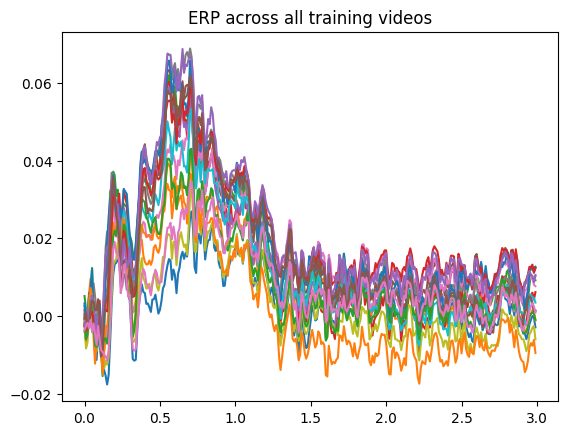

In [29]:
erp = trn_eeg.mean(0)          # average over all videos
plt.plot(times, erp.T); plt.title('ERP across all training videos')

The ERP plot shows a peak at ~0.1 s and again at 0.2–0.3 s, with the second peak higher.This is to be expected teh first peak is the P1/N1 effect range, reflecting the first pass of information through early visual cortex It's driven by low-level properties: contrast, luminance, spatial frequency, onset transients. For a static image this is where stimulus information peaks, because the whole stimulus arrives at once and is fully specified at t=0.
~0.2–0.3 s reflects recurrent and higher-level processing — feedback from downstream areas, category and semantic information, the N170/P2/N2 range. Representations here are more abstract and more stimulus-specific.

In [30]:
M = trn_eeg[:, :, 5:60].reshape(X_trn_p.shape[0], -1)
P = Y_pred_3d[:, :, 5:60].reshape(X_trn_p.shape[0], -1)
Mz = (M - M.mean(1, keepdims=True)) / M.std(1, keepdims=True)
Pz = (P - P.mean(1, keepdims=True)) / P.std(1, keepdims=True)

S = Mz @ Pz.T / M.shape[1]                          # (num_trails, num_trails) similarity
match = S.argmax(1)                                 # best predicted row per measured row

In [31]:
t = np.arange(X_trn_p.shape[0])
ranks = (-S).argsort(1).argsort(1)[t, t] + 1
print('top-1', (ranks == 1).mean(), 'top-5', (ranks <= 5).mean(), 'median', np.median(ranks))

top-1 0.78099173553719 top-5 0.8192148760330579 median 1.0


On the train EEG split, we can figure out what video evoked the brain activation 67\% of the time, indicating that we learned something, now we jus need to save the model for use on the test split

In [32]:
import joblib

joblib.dump({
    'sc': sc, 'pca': pca, 'sc2': sc2, 'model': model,
    'LAYER': LAYER, 'n_chan': n_chan, 'n_time': n_time,
    'DEC': DEC, 'SFREQ': SFREQ, 'N_FRAMES': N_FRAMES}, f'./encoder_sub-{SUB:02d}.joblib', compress=3)

['./encoder_sub-01.joblib']